# MODEL TRAINING
---
* OBJECTIVE: predict Delivery_Time_min. Main model: regularized linear regression (Ridge). Benchmark: CatBoost.

In [48]:
#Libraries
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))   
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from model_pipeline import config
from model_pipeline.preprocessing import load_data, split_data
from model_pipeline.train import cross_validate_models, build_ridge, build_catboost, evaluate
from model_pipeline.explain import linear_coefficients, permutation_table, catboost_shap
from model_pipeline.error_analysis import (build_error_frame, all_group_tables, worst_cases,
                                           interaction_table, error_summary)
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.base import clone
FIG_DIR = config.REPORTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)

## 1. DATA AND SPLIT

I hold out 20% of the rows as a test set. I use it once, at the end. Everything else (model choice, imputation, tuning) is decided with cross-validation on the train set.

In [14]:
df = load_data()
X_train, X_test, y_train, y_test = split_data(df)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Missing values in train:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

Train: (800, 7) | Test: (200, 7)
Missing values in train:
Courier_Experience_yrs    24
Weather                   22
Traffic_Level             19
Time_of_Day               24
dtype: int64


## 2. CROSS-VALIDATION OF THE CANDIDATES

- `baseline_mean`: always predicts the mean (the minimum to beat).
- `ridge_*`: the same Ridge model with three ways to impute the categorical columns (`missing` category, most frequent, random sample).
- `elasticnet_missing`: a linear model that can also set coefficients to zero.
- `catboost`: the benchmark.

The imputation is inside the pipeline, so it is fitted on each training fold only.

In [15]:
cv_results = cross_validate_models(X_train, y_train)
cv_results.round(3)

,model,rmse_mean,rmse_std,mae_mean,mae_std,r2_mean,r2_std
0,elasticnet_missing,10.975,0.687,6.770,0.420,0.753,0.034
1,ridge_missing,10.976,0.694,6.792,0.438,0.753,0.034
2,ridge_most_frequent,11.052,0.670,6.835,0.415,0.750,0.034
3,ridge_random,11.098,0.694,6.860,0.455,0.748,0.033
4,catboost,11.470,1.027,7.156,0.615,0.730,0.051
5,baseline_mean,22.290,0.795,17.920,0.397,-0.010,0.009


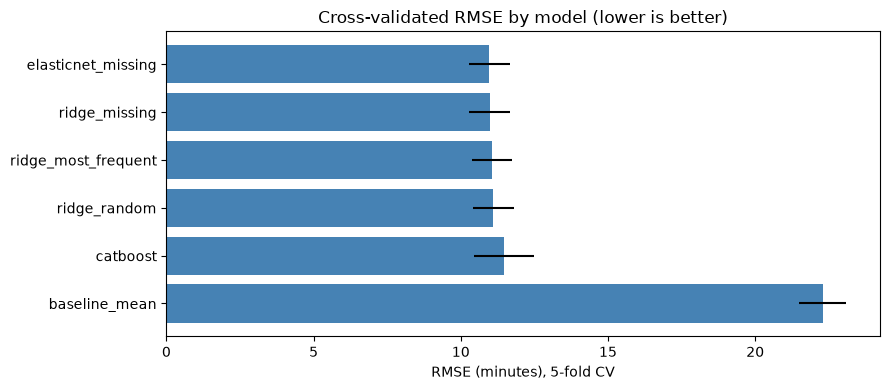

In [16]:
fig, ax = plt.subplots(figsize=(9, 4))
order = cv_results.sort_values("rmse_mean", ascending=False)
ax.barh(order["model"], order["rmse_mean"], xerr=order["rmse_std"], color="steelblue")
ax.set_xlabel("RMSE (minutes), 5-fold CV")
ax.set_title("Cross-validated RMSE by model (lower is better)")
plt.tight_layout()
plt.savefig(FIG_DIR / "cv_rmse.png", dpi=120)
plt.show()


- The ElasticNet model has the lowest rmse_mean, but the gap between it and ridge_missing is 0.0016 min (about 0.1 second). This difference is far smaller than the std (about 0.69), so it is a tie.</p>
- The rmse_mean values for missing, most frequent and random are 10.976, 11.052 and 11.098, respectively. That is a difference of about 4.56 seconds between "Missing" and "most frequent", and about 7.3 seconds between "Missing" and random. Both are far smaller than the std, so the imputation choice makes no measurable difference. So I'll keep creating the "Missing" category, because it is easier to explain to the business and to maintain over time.</p>
- The model type and the imputation choice don't make a measurable difference, and any of the linear options clearly beats the baseline. So the decision comes from other reasons: Ridge is simpler, its coefficients are easy to read and explain, and it is stable (std 0.69 vs 1.03 for CatBoost).

## 3. FINAL MODELS AND TEST SET

I fit Ridge and CatBoost on the full train set and evaluate once on the test set.

In [17]:
ridge = build_ridge("missing").fit(X_train, y_train)
catboost = build_catboost().fit(X_train, y_train)

test_results = pd.DataFrame({
    "ridge": evaluate(ridge, X_test, y_test),
    "catboost": evaluate(catboost, X_test, y_test),
}).T.round(3)
print("Chosen Ridge alpha:", ridge.named_steps["model"].alpha_)
test_results

Chosen Ridge alpha: 10.0


,rmse,mae,r2
ridge,8.762,5.931,0.829
catboost,9.209,6.268,0.811


## 4. EXPLAINABILITY

In [18]:
coefs = linear_coefficients(ridge)
coefs.round(2)

,feature,coefficient,abs_coefficient
0,num__Distance_km,16.97,16.97
1,num__Preparation_Time_min,6.95,6.95
2,cat__Traffic_Level_Low,-5.73,5.73
3,cat__Traffic_Level_High,4.97,4.97
4,cat__Time_of_Day_Missing,4.83,4.83
5,cat__Weather_Snowy,4.46,4.46
6,cat__Weather_Clear,-4.32,4.32
7,cat__Weather_Windy,-2.61,2.61
8,cat__Time_of_Day_Night,-1.99,1.99
9,num__Courier_Experience_yrs,-1.86,1.86


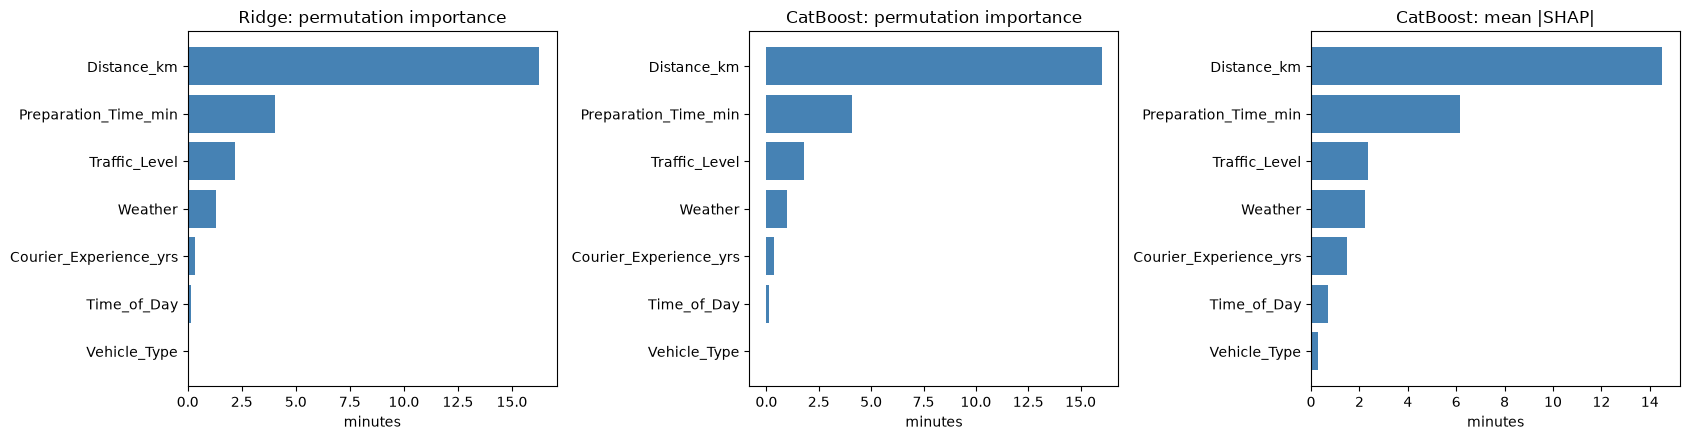

In [19]:
perm_ridge = permutation_table(ridge, X_test, y_test)
perm_cat = permutation_table(catboost, X_test, y_test)
shap_cat = catboost_shap(catboost, X_test)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, table, col, title in [
    (axes[0], perm_ridge, "rmse_increase_mean", "Ridge: permutation importance"),
    (axes[1], perm_cat, "rmse_increase_mean", "CatBoost: permutation importance"),
    (axes[2], shap_cat, "mean_abs_shap", "CatBoost: mean |SHAP|"),
]:
    t = table.sort_values(col)
    ax.barh(t["feature"], t[col], color="steelblue")
    ax.set_title(title)
    ax.set_xlabel("minutes")
plt.tight_layout()
plt.savefig(FIG_DIR / "feature_importance.png", dpi=120)
plt.show()

-  Distance matters most by far, then preparation time, then traffic and weather. Both models agree on the order. When I shuffle distance, the test RMSE goes up about 16 min in both Ridge (16.3) and CatBoost (16.0). Preparation time is next (4.0 and 4.1), then traffic (2.2 and 1.8) and weather (1.3 and 1.0). The SHAP values of CatBoost give the same order.</p>
-  This is not a surprise because the EDA already showed that order, and the models say the same. The EDA also showed that experience, time of day and vehicle add very little, and I see that here too.</p>
- The numeric features were scaled, so I divided each coefficient by the std of the feature to get minutes per unit. Each extra km adds about 3.0 min (16.97 / 5.72). Each extra preparation minute adds about 1.0 min (6.95 / 7.22), so the preparation time passes almost one to one to the delivery time. For traffic, High is +4.97 and Low is -5.73, so High traffic adds about 10.7 min compared with Low, all else equal. Weather goes from Clear (-4.32) to Snowy (+4.46), about 8.8 min.

## 5. ERROR ANALYSIS

Residual = real time - predicted time.

In [20]:
errors = build_error_frame(ridge, X_test, y_test)
pd.Series(error_summary(errors)).round(3)

rmse                       8.762
mae                        5.931
bias                      -0.780
share_error_over_10_min    0.170
share_underestimated       0.375
dtype: float64

In [21]:
tables = all_group_tables(errors)
for name, table in tables.items():
    print(f"--- {name} ---")
    display(table)

--- Weather ---


,n,bias_min,mae_min,share_underestimated
Weather,,,,
Foggy,21,5.82,9.76,0.67
Rainy,40,-1.21,6.40,0.38
Windy,16,1.12,6.13,0.44
Snowy,20,-0.85,6.10,0.40
Missing,8,-1.95,5.79,0.25
Clear,95,-2.27,4.83,0.31


--- Traffic_Level ---


,n,bias_min,mae_min,share_underestimated
Traffic_Level,,,,
High,38,2.83,8.01,0.47
Low,72,-2.05,6.00,0.32
Medium,79,-1.34,5.08,0.37
Missing,11,-0.94,4.45,0.45


--- Time_of_Day ---


,n,bias_min,mae_min,share_underestimated
Time_of_Day,,,,
Missing,6,-2.08,13.72,0.17
Afternoon,60,-0.78,6.69,0.38
Night,9,4.01,5.58,0.67
Evening,57,-1.67,5.36,0.30
Morning,68,-0.56,5.10,0.41


--- Vehicle_Type ---


,n,bias_min,mae_min,share_underestimated
Vehicle_Type,,,,
Bike,106,-0.49,6.16,0.40
Scooter,62,-1.05,6.11,0.32
Car,32,-1.21,4.82,0.41


--- distance_band ---


,n,bias_min,mae_min,share_underestimated
distance_band,,,,
15-20,52,0.05,8.59,0.44
10-15,47,-2.31,6.66,0.34
5-10,50,-0.92,4.59,0.42
0-5,51,-0.08,3.86,0.29


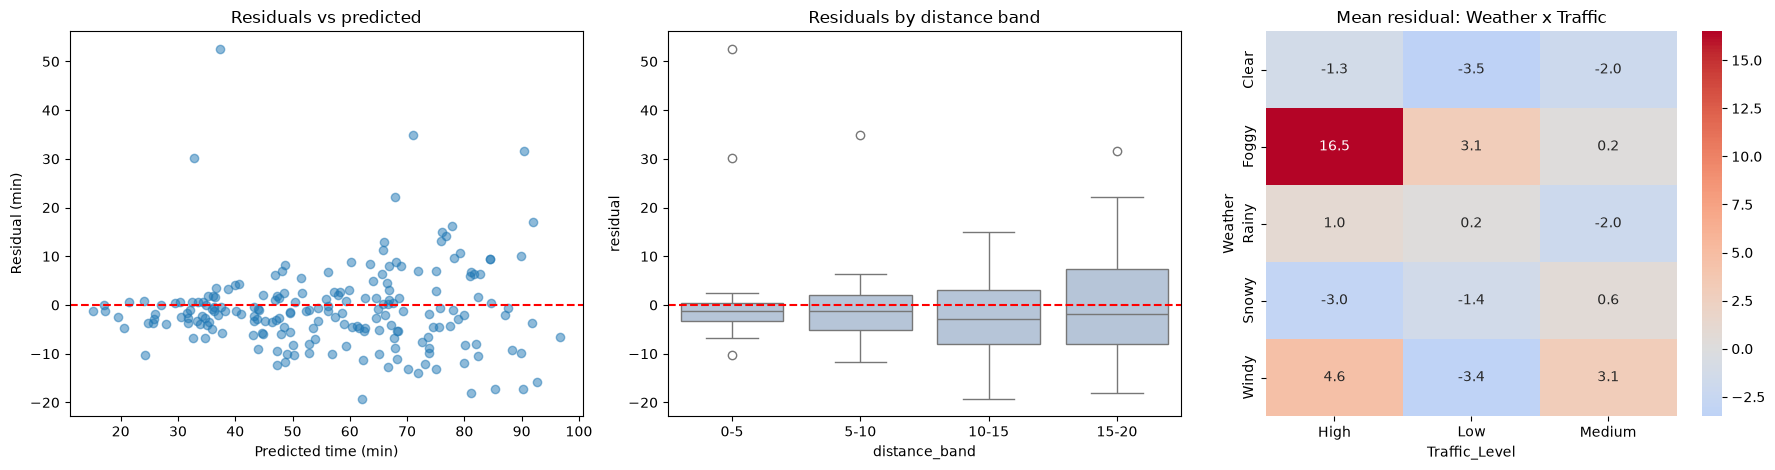

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

axes[0].scatter(errors["predicted"], errors["residual"], alpha=0.5)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Predicted time (min)"); axes[0].set_ylabel("Residual (min)")
axes[0].set_title("Residuals vs predicted")

sns.boxplot(data=errors, x="distance_band", y="residual", ax=axes[1], color="lightsteelblue")
axes[1].axhline(0, color="red", linestyle="--"); axes[1].set_title("Residuals by distance band")

sns.heatmap(interaction_table(errors, "Weather", "Traffic_Level"), annot=True, fmt=".1f",
            cmap="coolwarm", center=0, ax=axes[2])
axes[2].set_title("Mean residual: Weather x Traffic")
plt.tight_layout()
plt.savefig(FIG_DIR / "error_analysis.png", dpi=120)
plt.show()

In [23]:
worst_cases(errors, 10)

,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,actual,predicted,residual
859,3.0,9,5.0,Foggy,High,Afternoon,Bike,90,37.4,52.6
570,5.9,27,1.0,Foggy,High,NaN,Scooter,106,71.1,34.9
924,17.8,21,4.0,Windy,High,Evening,Bike,122,90.3,31.7
318,4.4,10,1.0,Foggy,Low,Morning,Scooter,63,32.9,30.1
260,16.4,7,NaN,Rainy,Medium,Night,Bike,90,67.8,22.2
879,13.6,12,2.0,Clear,Low,NaN,Scooter,43,62.2,-19.2
310,18.0,15,3.0,Snowy,Low,Afternoon,Bike,63,81.2,-18.2
86,19.0,26,5.0,Clear,Low,Afternoon,Car,68,85.3,-17.3
866,19.5,18,2.0,Clear,High,Morning,Bike,73,90.2,-17.2
595,19.7,27,6.0,Rainy,Low,Afternoon,Bike,109,92.0,17.0


  - The larger the distance, the larger the error. The MAE goes from 3.86 min (0-5 km) to 8.59 min (15-20 km). </p>
  - Fog (MAE 9.76) and high traffic (8.01) are also worse than the rest.</p>
  - Missing Time_of_Day has the highest MAE (13.72), but it is only 6 rows, so I don't trust it.</p>
  - On average it overestimates a little (bias -0.78 min), and about 62% of the deliveries are overestimated.</p>
  - In the bad cases (error over 10 min, 34 of 200) there are more overestimates (20) than underestimates (14).</p>
  - But the worst ones are underestimates: the top 5 errors are all underestimates, and the biggest is 52.6 min.</p>

## 6. SAVED FILES


In [24]:
sorted(p.name for p in config.ARTIFACTS_DIR.iterdir())

['metrics.json', 'model_catboost.joblib', 'model_ridge.joblib']

## 7. ANSWERS 

In [41]:
print("Ridge:", {k: round(v, 3) for k, v in error_summary(errors).items()})

Ridge: {'rmse': 8.762, 'mae': 5.931, 'bias': -0.78, 'share_error_over_10_min': 0.17, 'share_underestimated': 0.375}


In [42]:
bad = errors[errors["abs_error"] > 10]
print(f"Error > 10 min: {len(bad)} of {len(errors)} | "
      f"underestimated: {(bad['residual'] > 0).sum()} | overestimated: {(bad['residual'] < 0).sum()}")

Error > 10 min: 34 of 200 | underestimated: 14 | overestimated: 20


In [43]:
scaler = ridge.named_steps["preprocess"].named_transformers_["num"].named_steps["scaler"]
scales = pd.Series(scaler.scale_, index=config.NUM_COLS)
coef_num = coefs.set_index("feature").loc[[f"num__{c}" for c in config.NUM_COLS], "coefficient"]
per_unit = pd.Series(coef_num.values / scales.values, index=config.NUM_COLS)
print("\nStd of the numeric features (train):\n", scales.round(2))
print("\nMinutes per unit (coefficient / std):\n", per_unit.round(2))


Std of the numeric features (train):
 Distance_km               5.72
Preparation_Time_min      7.22
Courier_Experience_yrs    2.90
dtype: float64

Minutes per unit (coefficient / std):
 Distance_km               2.96
Preparation_Time_min      0.96
Courier_Experience_yrs   -0.64
dtype: float64


In [44]:
print("\nRidge permutation importance:\n", perm_ridge.round(2))
print("\nCatBoost permutation importance:\n", perm_cat.round(2))
print("\nCatBoost mean |SHAP|:\n", shap_cat.round(2))


Ridge permutation importance:
                   feature  rmse_increase_mean  rmse_increase_std
0             Distance_km               16.26               0.60
1    Preparation_Time_min                4.02               0.34
2           Traffic_Level                2.18               0.32
3                 Weather                1.32               0.16
4  Courier_Experience_yrs                0.36               0.08
5             Time_of_Day                0.13               0.07
6            Vehicle_Type                0.03               0.03

CatBoost permutation importance:
                   feature  rmse_increase_mean  rmse_increase_std
0             Distance_km               16.00               0.60
1    Preparation_Time_min                4.09               0.36
2           Traffic_Level                1.78               0.28
3                 Weather                0.97               0.16
4  Courier_Experience_yrs                0.34               0.10
5             Time_of_D

In [ ]:
foggy = errors[errors["Weather"] == "Foggy"].sort_values("residual", ascending=False)
print("Test, Foggy: n =", len(foggy), "| bias =", round(foggy["residual"].mean(), 2),
      "| median =", round(foggy["residual"].median(), 2))
print("Top 3 residuals:", foggy["residual"].head(3).round(1).tolist())
print("Bias without the top 3:", round(foggy["residual"].iloc[3:].mean(), 2))


Test, Foggy: n = 21 | bias = 5.82 | median = 1.35
Top 3 residuals: [52.6, 34.9, 30.1]
Bias without the top 3: 0.25


*  Rainy is not underestimated (bias -1.2). Foggy shows +5.82 in the test set, but 3 cases drive it (0.25 without them) and it is +0.45 out of fold, so it is not systematic.

In [49]:
oof = cross_val_predict(clone(ridge), X_train, y_train,
                        cv=KFold(5, shuffle=True, random_state=config.RANDOM_STATE))
oof_res = pd.DataFrame({"Weather": X_train["Weather"].fillna("Missing"), "residual": y_train - oof})
print("\nOut-of-fold residuals on the train set, by weather:")
print(oof_res.groupby("Weather")["residual"].agg(n="size", bias="mean", median="median").round(2))


Out-of-fold residuals on the train set, by weather:
           n  bias  median
Weather                   
Clear    375 -0.17   -1.56
Foggy     82  0.45   -1.86
Missing   22  0.61   -4.59
Rainy    164  0.14   -1.67
Snowy     77  0.60   -0.41
Windy     80 -0.30   -0.79
